In [27]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
print("libaries imported successfully")

libaries imported successfully


In [28]:
housing=fetch_california_housing(as_frame=True)
df=housing.frame
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [29]:
print("Dataset shape:",df.shape)
print("\nColumns names:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nStatistical summary:")
df.describe()

Dataset shape: (20640, 9)

Columns names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


mean hosue value: 2.0685581690891475
medain hosue value: 1.797
Minimum house value: 0.14999
Maximum house value: 5.00001


Text(0.5, 1.0, ' Distribution of Median House Values ')

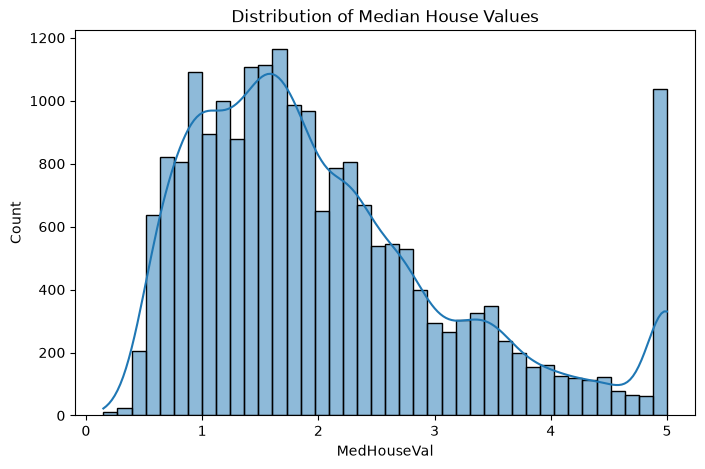

In [30]:
print("mean hosue value:",df["MedHouseVal"].mean())
print("medain hosue value:",df["MedHouseVal"].median())
print("Minimum house value:",df["MedHouseVal"].min())
print("Maximum house value:",df["MedHouseVal"].max())

plt.figure(figsize=(8,5))
sns.histplot(df["MedHouseVal"],bins=40,kde=True)
plt.title(" Distribution of Median House Values ")

In [31]:
correlation_matrix=df.corr()
correlation_matrix

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


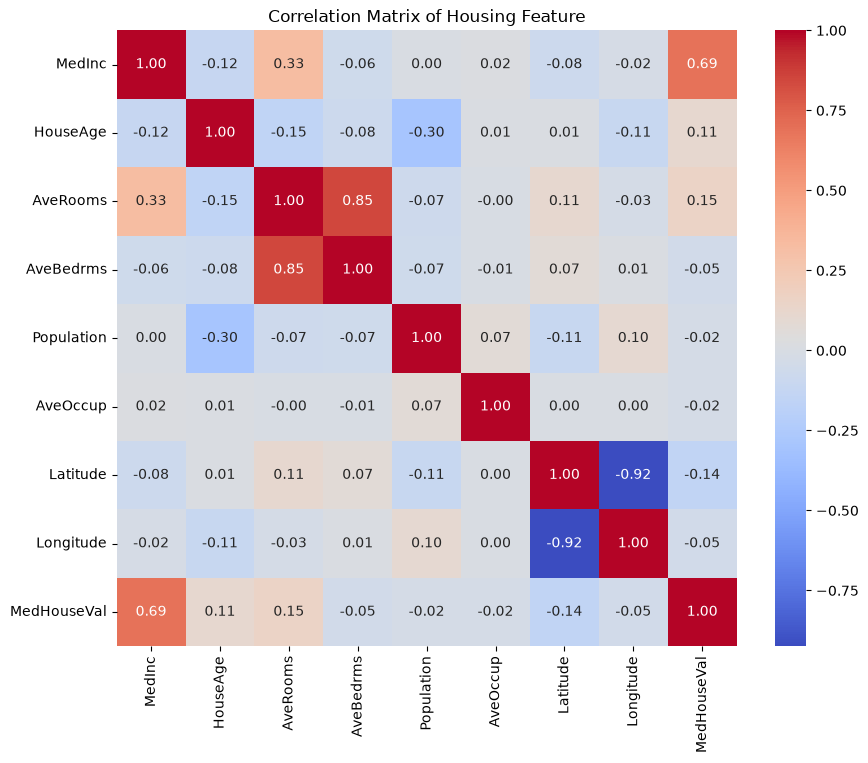

In [32]:
plt.figure(figsize=(10,8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title(" Correlation Matrix of Housing Feature ")
plt.show()

In [33]:
price_correlation= correlation_matrix["MedHouseVal"]
price_correlation=price_correlation.drop("MedHouseVal")
price_correlation=price_correlation.sort_values(
    ascending=False
)
print(price_correlation)

MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64


In [34]:
x=df.drop("MedHouseVal",axis=1)
y=df["MedHouseVal"]
print("Feature shape :",x.shape)
print("Target shape:",y.shape)


Feature shape : (20640, 8)
Target shape: (20640,)


In [35]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)
print("Training observations :", x_train.shape[0])
print("Testing Observation :",x_test.shape[0])


Training observations : 16512
Testing Observation : 4128


In [36]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)
print("Model trained successfully! ")
y_pred=model.predict(x_test)
print("First 10 actual values: ")
print(y_test.iloc[:10].values)
print("\nFirst 10 predicted values : ")
print(y_pred[:10])

Model trained successfully! 
First 10 actual values: 
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

First 10 predicted values : 
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [25]:
import joblib

joblib.dump(model, "linear_regression_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [26]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error,r2_score
mae=mean_absolute_error(y_test,y_pred)
rsme=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print("MAE:",mae)
print("RMSE:",rsme)
print("R2 score:",r2)

MAE: 0.5332001304956555
RMSE: 0.5558915986952442
R2 score: 0.575787706032451
